# Feature selection for Titanic survival prediction

In [1]:
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from titanic.data import (
    load_titanic_data, summarise_missing_data,
    summarise_unique_values, summarise_survival,
)
from titanic.features import (
    add_sex_pclass, add_family_size, add_family_type,
    parse_names_execution, add_aggregated_titles,
)
import titanic.plots as plots
importlib.reload(plots)
from titanic.plots import plot_counts, plot_distributions, label_survival_rates, rate_and_n, export_figure

DATA_DIR = "data"
FIGURES_DIR = "figures/report"
TARGET = "Survived"
COLOR_LIST = ["#A5D7E8", "#576CBC", "#19376D", "#0b2447"]
SURVIVAL_PALETTE = {0: COLOR_LIST[1], 1: COLOR_LIST[0]}
FIGSIZE = (8, 4)
HIST_BINS = 30
NAME_COLUMNS = ["Family Name", "Title", "Given Name", "Maiden Name"]

train_df, test_df = load_titanic_data(DATA_DIR)

assert len(train_df) == 891 and train_df[TARGET].notna().all()

## 1. Initial exclusion for missing values and less meaningful variables

We observed 77.1% values are missing for the variable Cabin, so it is excluded from feature selection. Passenger ID, Name, and Ticket are also excluded because most of their values are unique and they mainly serve as identifiers. Age also has a relatively high missing rate but can still be considered after creating a missing indicator. The other variables are considered further in following steps

In [2]:
missing = summarise_missing_data(train_df)
unique = summarise_unique_values(train_df)
audit = missing.join(unique[["Uniques"]]).drop(index=TARGET)
audit = audit.rename(columns={
    "Total": "Missing (n)", "Percent": "Missing (%)", "Uniques": "Unique values",
})
display(audit.round({"Missing (%)": 1}))

EXCLUDED_RAW_FEATURES = ["PassengerId", "Name", "Ticket", "Cabin"]

,Missing (n),Missing (%),Types,Unique values
PassengerId,0,0.0,int64,891
Pclass,0,0.0,int64,3
Name,0,0.0,str,891
Sex,0,0.0,str,2
Age,177,19.9,float64,88
SibSp,0,0.0,int64,7
Parch,0,0.0,int64,7
Ticket,0,0.0,str,681
Fare,0,0.0,float64,248
Cabin,687,77.1,str,147


In [3]:
train_df = add_sex_pclass(train_df)
train_df = add_family_size(train_df)
train_df = add_family_type(train_df)
train_df = parse_names_execution(train_df, NAME_COLUMNS)
train_df = add_aggregated_titles(train_df)
train_df["Family Type"] = pd.Categorical(
    train_df["Family Type"], categories=["Single", "Small", "Large"], ordered=True,
)
train_df["LogFare"] = np.log1p(train_df["Fare"])

## 2. Sex and passenger class

Female has much higher survival rate than male. However, within each sex group, both decrease from first class to third class, with female survival rate reduced from 96.8% to 50.0% and male survival rate reduced from 36.9% to 13.5%.

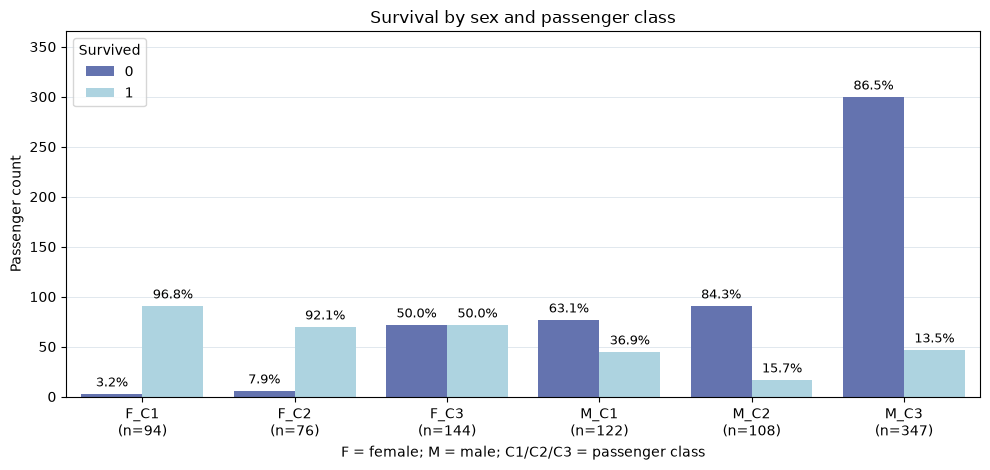

In [4]:
plot_df = train_df.sort_values("Sex_Pclass")
fig = plot_counts(plot_df, "Sex_Pclass", TARGET, SURVIVAL_PALETTE, (10, 4.8))
ax = fig.axes[0]
label_survival_rates(ax, plot_df, "Sex_Pclass")
ax.set_title("Survival by sex and passenger class")
ax.set_xlabel("F = female; M = male; C1/C2/C3 = passenger class")
fig.tight_layout()
export_figure(fig, "01_sex_and_class.png", FIGURES_DIR)

## 3. Age

Missing ages are excluded from the analysis. Young passengers have similar surval rates across male and female, at around 55%-60% for age group under 12. However, adult passengers behave differently by sex, with 75.2% survival rate for female, versus 17.0% for male.

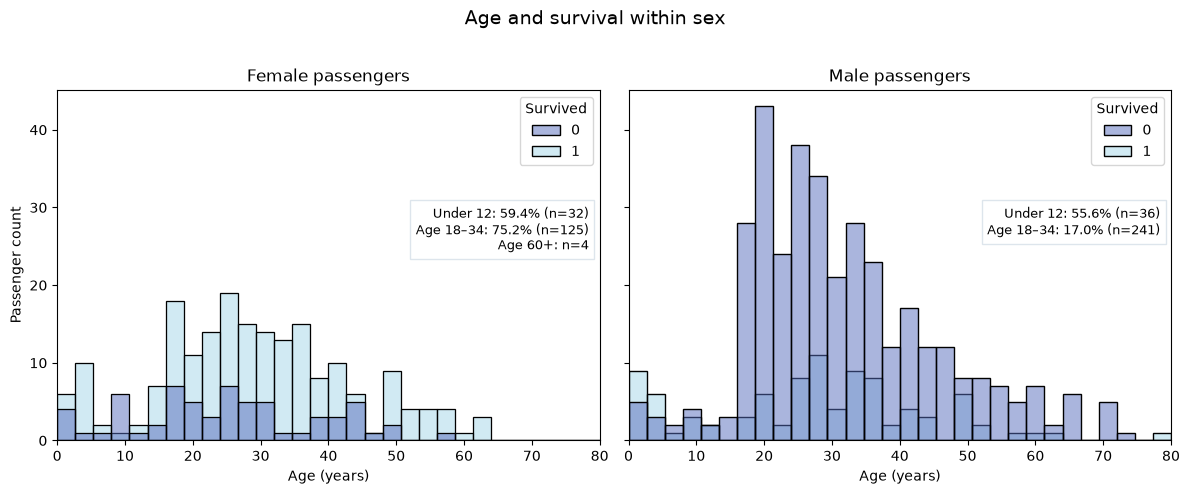

In [5]:
age_bins = np.linspace(0, 80, HIST_BINS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, sex in zip(axes, ["female", "male"]):
    subset = train_df.loc[train_df["Sex"].eq(sex) & train_df["Age"].notna()]
    plot_distributions(subset, "Age", TARGET, SURVIVAL_PALETTE, FIGSIZE, age_bins, ax=ax)
    children = subset.loc[subset["Age"] < 12]
    adults = subset.loc[subset["Age"].between(18, 35, inclusive="left")]
    note = f"Under 12: {rate_and_n(children)}\nAge 18–34: {rate_and_n(adults)}"
    if sex == "female":
        note += f"\nAge 60+: n={subset['Age'].ge(60).sum()}"
    ax.text(0.98, 0.67, note, transform=ax.transAxes, ha="right", va="top", fontsize=9,
            bbox={"facecolor": "white", "edgecolor": "#DCE4EB", "alpha": 0.95})
    ax.set_title(f"{sex.capitalize()} passengers")
    ax.set_xlabel("Age (years)")
    ax.set_ylabel("Passenger count")
    ax.set_xlim(0, 80)
fig.suptitle("Age and survival within sex", fontsize=14, y=1.02)
fig.tight_layout()
export_figure(fig, "02_age_by_sex.png", FIGURES_DIR)

## 4. Fare

We took the logworth value of fare and compare its median within each Class. First-class and second-class survivors’ median fare is almost the double of non-survivors, while third-class fare medians are very close. This variable overlaps with Class but could possibly help split First- and Second- Class into further subgroups.

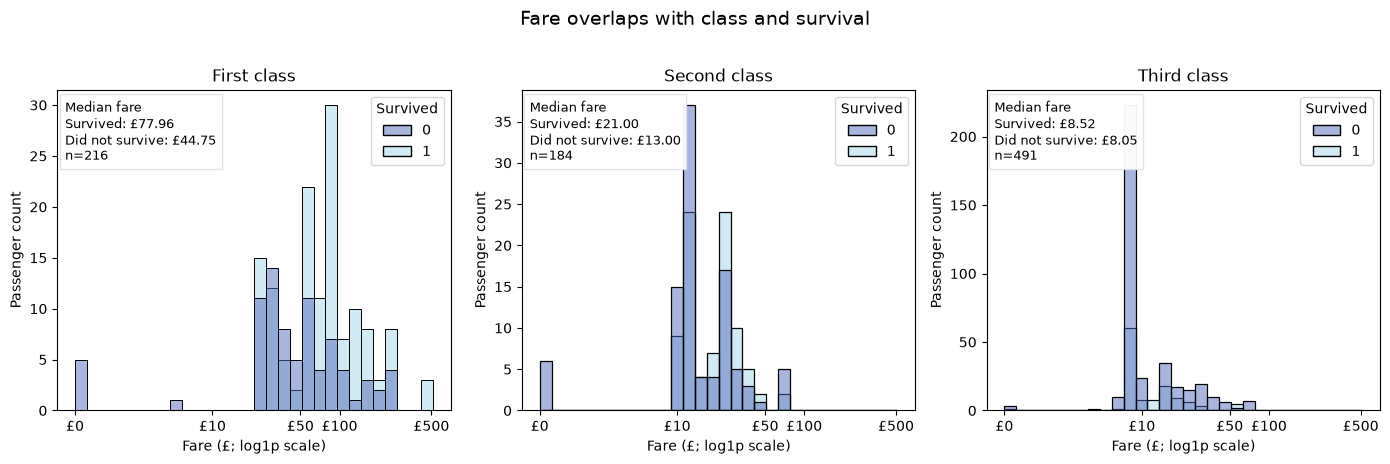

In [6]:
fare_bins = np.linspace(0, train_df["LogFare"].max(), HIST_BINS + 1)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True)
for ax, pclass, title in zip(axes, [1, 2, 3], ["First class", "Second class", "Third class"]):
    subset = train_df.loc[train_df["Pclass"].eq(pclass)]
    plot_distributions(subset, "LogFare", TARGET, SURVIVAL_PALETTE, FIGSIZE, fare_bins, ax=ax)
    medians = subset.groupby(TARGET)["Fare"].median()
    note = (f"Median fare\nSurvived: £{medians.loc[1]:.2f}\n"
            f"Did not survive: £{medians.loc[0]:.2f}\nn={len(subset)}")
    ax.text(0.02, 0.97, note, transform=ax.transAxes, ha="left", va="top", fontsize=9,
            bbox={"facecolor": "white", "edgecolor": "#DCE4EB", "alpha": 0.95})
    ax.set_title(title)
    fare_ticks = np.array([0, 10, 50, 100, 500])
    ax.set_xticks(np.log1p(fare_ticks), [f"£{value}" for value in fare_ticks])
    ax.set_xlabel("Fare (£; log1p scale)")
    ax.set_ylabel("Passenger count")
fig.suptitle("Fare overlaps with class and survival", fontsize=14, y=1.02)
fig.tight_layout()
export_figure(fig, "03_fare_within_class.png", FIGURES_DIR)

## 5. Family size

Small families and single person tend to have higher survival rate than large families overall. This could be because members of larger families may delay their escape while trying to keep the family together.

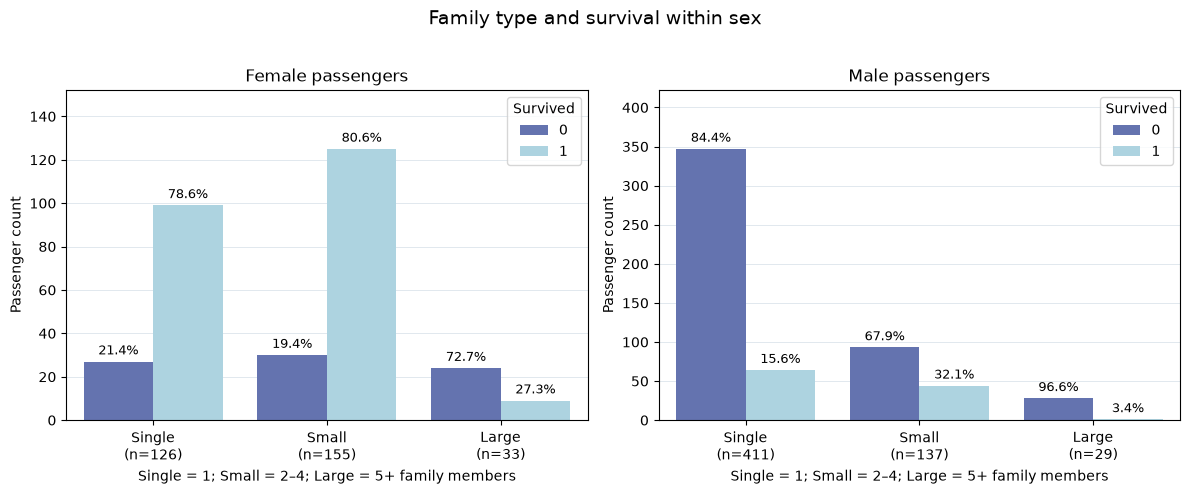

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

for ax, sex in zip(axes, ["female", "male"]):
    subset = train_df.loc[train_df["Sex"].eq(sex)]
    plot_counts(
        subset, "Family Type", TARGET,
        SURVIVAL_PALETTE, FIGSIZE, ax=ax,
    )
    label_survival_rates(ax, subset, "Family Type")
    ax.set_title(f"{sex.capitalize()} passengers")
    ax.set_xlabel("Single = 1; Small = 2–4; Large = 5+ family members")

fig.suptitle("Family type and survival within sex", fontsize=14, y=1.02)
fig.tight_layout()
export_figure(fig, "04_family_type_by_sex.png", FIGURES_DIR)

## 6. Title

Title helps split male group into further subgroups such as "Master", which has much higher survival rate compared to other titles.

In [9]:
title_summary = summarise_survival(train_df)
title_counts = (
    train_df.groupby(["Titles", "Sex"])
    .size()
    .rename("n")
    .reset_index()
)

title_summary = title_summary.merge(title_counts, on=["Titles", "Sex"])
title_summary["Survived"] = title_summary["Survived"].mul(100).round(1)

display(title_summary.rename(columns={"Survived": "Survival (%)"}))

,Titles,Sex,Survival (%),n
0,Master.,male,57.5,40
1,Miss.,female,70.3,185
2,Mr.,male,15.7,517
3,Mrs.,female,79.4,126
4,Rare,female,100.0,3
5,Rare,male,25.0,20


## 6. Summary
Sex, passenger class, fare, age, family size and title have shown good discrimination across each group. Hence, they are selected as candidate features for the survival prediction.